# Which TGLF/GFTM settings minimise the predicted flux error on the 738 GS2-KBMs? (WP3, `Fusion_PhD-qp5.53`)

Work package 3 of `results/flux_metric_sensitivity` (Fusion_PhD). It takes the per-mode linear ingredients of pyrokinetics' MG
saturation rule (`giacomin_quasi-linear_2025`) for every GS2-KBM and every existing fixed-WIDTH × NBASIS and GHAT setting, and
turns their errors against GS2 into a predicted flux error with the elasticities of WP1/WP2.

For one mode at one $k_y$, the MG rule's per-$k_y$ quantity is $\Lambda_k=\gamma\,S$, with $S=\sum_f A_fE_f$, $A_f$ the field
amplitude ratio and $E_f=\langle|f|^2\rangle/\langle k_\perp^2|f|^2\rangle$ the field extent. Per mode:
$$\ln\frac{\Lambda_k^{\rm code}}{\Lambda_k^{\rm GS2}}=\underbrace{\ln\frac{\gamma^{\rm code}}{\gamma^{\rm GS2}}}_{\gamma\ \rm term}
  +\underbrace{\ln\frac{S^{\rm code}}{S^{\rm GS2}}}_{A\ \rm term\ +\ E\ \rm term},$$
with the $S$ term split exactly into an amplitude and an extent part by the two-player Shapley rule (as in WP2).

**Predicted flux errors** (a uniform error at every $k_y$, WP1):
- MG rule: $\delta_{\rm MG}=\alpha\,\ln(\Lambda_k^{\rm code}/\Lambda_k^{\rm GS2})$, $\alpha=2.5$.
- TGLF SAT1/2/3: $\delta_{\rm SAT}=2\ln(\gamma^{\rm code}/\gamma^{\rm GS2})+\ln(W_{\rm QL}^{\rm code}/W_{\rm QL}^{\rm GS2})$. The
  linear TGLF/GFTM outputs hold no QL weights, so the $W_{\rm QL}$ term is left out here (it is measured on the $\beta$ scans
  by `Fusion_PhD-qp5.54`); $\delta_{\rm SAT}$ below is its $\gamma$ part.

A mode the code does not find (no mode with $\gamma>0$ and $\omega>0$) has an infinite error, as in
`width_nbasis_fractions.ipynb`; every fraction is over all 738.

**Data**, all existing: the `kbm_free` GS2 cubes; TGLF `fx_fm1p5_*` (SAT_RULE 2, FILTER $-1.5$, NXGRID 32) and `gh*_nb24`
(GHAT at WIDTH 0.4, NBASIS 24); GFTM `galF_*` (FILTER 0.5, NXGRID $\ge$ NBASIS + 8). Catalogue: Fusion_PhD
`docs/gyro_data_runs.md`, sections "`kbm_free` fixed WIDTH × NBASIS" and "TGLF `kbm_free`: GHAT".

*AI use: written and run by an AI agent (Claude). The numbers are advisory until checked.*

In [1]:
import os
import re
from multiprocessing import get_context
from pathlib import Path
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.saturation_rules import SaturationRules

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plot_dir = ROOT / "Plots" / "flux_metric_sensitivity"
(plot_dir / "plots").mkdir(parents=True, exist_ok=True)
(plot_dir / "csv").mkdir(parents=True, exist_ok=True)

cases = ["SPR-045", "M1", "R4", "R3"]
widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6,
          1.9218, 2.3083, 2.7726, 3.3302, 4.0]
cells = {"TGLF": [(2, 32), (4, 32), (6, 32), (8, 32), (12, 32), (16, 32), (24, 32)],
         "GFTM": [(2, 32), (4, 32), (8, 32), (12, 32), (16, 32), (24, 32), (32, 40), (48, 65), (56, 64)]}
ghats = {0.0: "gh0", 0.05: "gh0p05", 0.1: "gh0p1", 0.2: "gh0p2", 0.25: "gh0p25", 0.3: "gh0p3", 0.35: "gh0p35", 0.4: "gh0p4",
         0.45: "gh0p45", 0.5: "gh0p5", 0.6: "gh0p6", 0.75: "gh0p75"}
alpha = 2.5                           # MG exponent: Q = Q0 Lambda^alpha (pyro default)
tolerances = [0.05, 0.10, 0.20]       # gamma within x of GS2, as width_nbasis_fractions.ipynb
flux_factors = [1.5, 2.0, 3.0]        # predicted Q within this factor of GS2's
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))
fields = ["phi", "apar", "bpar"]


def leaf_path(code, case, width, nbasis, nxgrid, ghat=None):
    if ghat is not None:
        return data_root / "TGLF/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"{ghats[ghat]}_nb{nbasis}"
    width_tag = f"w{width:.4f}".replace(".", "p")
    if code == "TGLF":
        return data_root / "TGLF/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"fx_fm1p5_{width_tag}_nb{nbasis}"
    return data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{width_tag}_nb{nbasis}_nx{nxgrid}"


def units_tag(quantity):
    return re.sub(r"_pyroscan_base\d+", "", str(quantity.data.units))


def ingredient_table(ingredients):
    # one row per sample: gamma, A_f and E_f of each field (ingredients already reduced to one mode)
    table = pd.DataFrame({"sample": [str(name) for name in ingredients.sample.values],
                          "gamma_mg": ingredients.growth_rate.pint.dequantify().values})
    for field in fields:
        table[f"amplitude_{field}"] = ingredients.field_amplitude.sel(field=field).pint.dequantify().values
        table[f"extent_{field}"] = ingredients.field_extent.sel(field=field).pint.dequantify().values
    table["extent_units"] = units_tag(ingredients.field_extent)
    return table

## GS2: MG ingredients of the 738 KBMs
`gamma_tolerance` is $\infty$ here: these are the database's own modes, and 738/738 have `growth_rate_tolerance` below 0.05
(`basis_resolution_rule`). The fraction below $10^{-3}$, the MG default, is printed.

In [2]:
gs2_rows = []
for case in cases:
    leaf = data_root / "GS2/Runs/LATIN_HYPERCUBE" / case / "kbm_free"
    gs2_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    population = list(PyroHypercube(pyroscan_json=leaf_path("GFTM", case, 1.0, 16, 32) / "pyroscan.json", load_base_pyro=True).pyro_dict)
    gs2_ingredients = SaturationRules(gs2_scan).mg_ingredients(gamma_tolerance=np.inf).squeeze("theta0", drop=True)
    gs2_ingredients = gs2_ingredients.drop_vars(["heat_fraction", "particle_fraction"]).set_index(sample="sample_name").sel(sample=population)
    gs2_output = gs2_scan.gk_output.data.set_index(sample="sample_name").sel(sample=population)
    table = ingredient_table(gs2_ingredients).add_suffix("_gs2").rename(columns={"sample_gs2": "sample"})
    table["case"] = case
    table["gamma_units_gs2"] = units_tag(gs2_output.growth_rate)
    table["tolerance_gs2"] = gs2_output.growth_rate_tolerance.pint.dequantify().values
    table["ky"] = gs2_output.ky.values
    gs2_rows.append(table)
gs2 = pd.concat(gs2_rows, ignore_index=True)
assert len(gs2) == 738, len(gs2)
assert (gs2.gamma_mg_gs2 > 0).all()
print("GS2 KBMs with growth_rate_tolerance < 1e-3:", int((gs2.tolerance_gs2 < 1e-3).sum()), "of", len(gs2))
gs2.groupby("case")[["amplitude_apar_gs2", "extent_phi_gs2"]].median().round(4)

GS2 KBMs with growth_rate_tolerance < 1e-3: 548 of 738


,amplitude_apar_gs2,extent_phi_gs2
case,,
M1,0.5612,23.0575
R3,0.6272,17.3975
R4,0.6517,8.2253
SPR-045,0.6598,3.2936


## Code runs: MG ingredients of the dominant mode, for every setting
The dominant mode is the argmax of $\gamma$ over `mode`. "Found" is $\gamma>0$ and $\omega>0$ (ion direction), as before.

In [3]:
def load_leaf(spec):
    code, case, width, nbasis, nxgrid, ghat = spec
    path = leaf_path(code, case, width, nbasis, nxgrid, ghat)
    scan = PyroHypercube(pyroscan_json=path / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=path / "pyroscan.nc")
    output = scan.gk_output.data
    dominant = output.growth_rate.pint.dequantify().fillna(-np.inf).argmax("mode")
    ingredients = SaturationRules(scan).mg_ingredients(gamma_tolerance=np.inf).squeeze("theta0", drop=True).isel(mode=dominant)
    ingredients = ingredients.set_index(sample="sample_name")
    output = output.isel(mode=dominant).set_index(sample="sample_name")
    table = ingredient_table(ingredients)
    table = table.assign(code=code, case=case, width=width, nbasis=nbasis, ghat=1.0 if ghat is None else ghat,
                         family="ghat" if ghat is not None else "fixed",
                         gamma=output.growth_rate.pint.dequantify().values, omega=output.mode_frequency.pint.dequantify().values,
                         gamma_units=units_tag(output.growth_rate))
    return table


specs = [(code, case, width, nbasis, nxgrid, None) for code in cells for case in cases for width in widths for nbasis, nxgrid in cells[code]]
specs += [("TGLF", case, 0.4, 24, 32, ghat) for case in cases for ghat in ghats]
with get_context("fork").Pool(n_cpu) as pool:
    runs = pd.concat(pool.map(load_leaf, specs, chunksize=2), ignore_index=True)
runs = runs.merge(gs2, on=["case", "sample"], validate="many_to_one")
settings = ["code", "family", "width", "nbasis", "ghat"]
assert (runs.groupby(settings).size() == 738).all()
assert (runs.gamma_units == runs.gamma_units_gs2).all(), "code and GS2 growth rates are not in the same normalisation"
assert (runs.extent_units == runs.extent_units_gs2).all(), "code and GS2 field extents are not in the same normalisation"
runs["found"] = (runs.gamma > 0) & (runs.omega > 0)
print("leaves:", len(specs), "| settings:", runs.groupby(settings).ngroups, "| rows:", len(runs))

leaves: 1584 | settings: 396 | rows: 292248


## Per-mode errors and predicted flux errors
$S(A,E)=\sum_fA_fE_f$; the amplitude term is $\tfrac12[\ln S(A^c,E^c)/S(A^g,E^c)+\ln S(A^c,E^g)/S(A^g,E^g)]$ and the extent
term is the rest of $\ln(S^c/S^g)$.

In [4]:
def field_sum(table, amplitude_suffix, extent_suffix):
    return sum(table[f"amplitude_{field}{amplitude_suffix}"] * table[f"extent_{field}{extent_suffix}"] for field in fields)


s_code, s_gs2 = field_sum(runs, "", ""), field_sum(runs, "_gs2", "_gs2")
s_gs2_amplitude, s_gs2_extent = field_sum(runs, "_gs2", ""), field_sum(runs, "", "_gs2")
runs["gamma_term"] = np.log(runs.gamma / runs.gamma_mg_gs2)
runs["amplitude_term"] = 0.5 * (np.log(s_code / s_gs2_amplitude) + np.log(s_gs2_extent / s_gs2))
runs["extent_term"] = np.log(s_code / s_gs2) - runs.amplitude_term
runs["error_mg"] = alpha * (runs.gamma_term + runs.amplitude_term + runs.extent_term)
runs["error_sat_gamma"] = 2.0 * runs.gamma_term
# the same MG error with B_par left out of S in both codes, and each field's amplitude ratio
no_bpar = [field for field in fields if field != "bpar"]
runs["error_mg_no_bpar"] = alpha * (runs.gamma_term + np.log(
    sum(runs[f"amplitude_{f}"] * runs[f"extent_{f}"] for f in no_bpar) / sum(runs[f"amplitude_{f}_gs2"] * runs[f"extent_{f}_gs2"] for f in no_bpar)))
for field in ["apar", "bpar"]:
    runs[f"log_amplitude_{field}"] = np.log(runs[f"amplitude_{field}"] / runs[f"amplitude_{field}_gs2"])
runs["bpar_share_of_s"] = runs.amplitude_bpar * runs.extent_bpar / s_code
runs["bpar_share_of_s_gs2"] = runs.amplitude_bpar_gs2 * runs.extent_bpar_gs2 / s_gs2
for column in ["gamma_term", "amplitude_term", "extent_term", "error_mg", "error_sat_gamma", "error_mg_no_bpar"]:
    runs.loc[~runs.found, column] = np.inf
assert np.isfinite(runs.loc[runs.found, "error_mg"]).all()


def summarise(group):
    found = group[group.found]
    row = {"found": group.found.mean()}
    for tolerance in tolerances:
        row[f"gamma_within_{tolerance:.0%}"] = (abs(np.exp(group.gamma_term) - 1) <= tolerance).mean()
    for factor in flux_factors:
        row[f"q_mg_within_x{factor:g}"] = (abs(group.error_mg) <= np.log(factor)).mean()
        row[f"q_sat_gamma_within_x{factor:g}"] = (abs(group.error_sat_gamma) <= np.log(factor)).mean()
    row["median_abs_error_mg"] = abs(group.error_mg).median()      # misses count as infinite
    row["median_abs_error_sat_gamma"] = abs(group.error_sat_gamma).median()
    row["q_mg_no_bpar_within_x2"] = (abs(group.error_mg_no_bpar) <= np.log(2.0)).mean()
    row["median_abs_error_mg_no_bpar"] = abs(group.error_mg_no_bpar).median()
    for column in ["log_amplitude_apar", "log_amplitude_bpar", "bpar_share_of_s", "bpar_share_of_s_gs2"]:
        row[f"median_{column}_found"] = found[column].median()
    for term in ["gamma_term", "amplitude_term", "extent_term"]:
        row[f"median_{term}_found"] = found[term].median()
        row[f"median_abs_{term}_found"] = abs(found[term]).median()
    return pd.Series(row)


ranked = runs.groupby(settings).apply(summarise).reset_index()
for metric in ["gamma_within_20%", "q_sat_gamma_within_x2", "q_mg_within_x2", "q_mg_no_bpar_within_x2"]:
    ranked[f"rank_{metric}"] = ranked.groupby(["code", "family"])[metric].rank(ascending=False, method="min")
ranked.to_csv(plot_dir / "csv" / "settings_ranked_by_flux_metric.csv", index=False, float_format="%.4g")

## Check: the $\gamma$-only limit reproduces the existing $\gamma$-within-$x$ fractions
The `gamma_within_*` columns use the same population, mode choice and miss rule as `width_nbasis_fractions.ipynb`
(`basis_resolution_rule/csv/fractions_within_x.csv`) and the GHAT study (`tglf_ghat_database/csv/summary_by_ghat_nb24.csv`), and
are compared with them in Fusion_PhD. Here: does ranking by the flux metric change the order?

In [5]:
for (code, family), group in ranked.groupby(["code", "family"]):
    rho = group[["gamma_within_20%", "q_sat_gamma_within_x2", "q_mg_within_x2", "q_mg_no_bpar_within_x2"]].corr(method="spearman")
    print(f"{code} {family}: Spearman rank correlation over {len(group)} settings | gamma 20% vs SAT(gamma) x2: "
          f"{rho.iloc[0, 1]:.3f} | gamma 20% vs MG x2: {rho.iloc[0, 2]:.3f} | gamma 20% vs MG without B_par x2: {rho.iloc[0, 3]:.3f}")
top = (ranked.sort_values("q_mg_within_x2", ascending=False).groupby(["code", "family"]).head(5)
       [settings + ["found", "gamma_within_20%", "q_sat_gamma_within_x2", "q_mg_within_x2", "median_abs_error_mg",
                    "median_gamma_term_found", "median_amplitude_term_found", "median_extent_term_found"]])
top.round(3)

GFTM fixed: Spearman rank correlation over 216 settings | gamma 20% vs SAT(gamma) x2: 0.996 | gamma 20% vs MG x2: -0.387 | gamma 20% vs MG without B_par x2: 0.738
TGLF fixed: Spearman rank correlation over 168 settings | gamma 20% vs SAT(gamma) x2: 0.986 | gamma 20% vs MG x2: 0.336 | gamma 20% vs MG without B_par x2: 0.450
TGLF ghat: Spearman rank correlation over 12 settings | gamma 20% vs SAT(gamma) x2: 0.346 | gamma 20% vs MG x2: 0.123 | gamma 20% vs MG without B_par x2: -0.099


,code,family,width,nbasis,ghat,found,gamma_within_20%,q_sat_gamma_within_x2,q_mg_within_x2,median_abs_error_mg,median_gamma_term_found,median_amplitude_term_found,median_extent_term_found
127,GFTM,fixed,1.200,4,1.00,0.744,0.176,0.305,0.183,2.471,-0.054,0.990,-0.981
99,GFTM,fixed,0.900,2,1.00,0.878,0.121,0.213,0.183,2.265,0.592,0.399,-0.670
118,GFTM,fixed,1.100,4,1.00,0.789,0.203,0.343,0.180,2.341,-0.024,0.966,-0.845
108,GFTM,fixed,1.000,2,1.00,0.840,0.133,0.218,0.178,2.406,0.531,0.382,-0.939
334,TGLF,fixed,1.400,24,1.00,0.844,0.096,0.165,0.176,2.525,0.910,-0.478,-0.075
117,GFTM,fixed,1.100,2,1.00,0.825,0.126,0.234,0.168,2.383,0.427,0.394,-1.112
319,TGLF,fixed,1.200,16,1.00,0.812,0.117,0.201,0.160,2.598,0.769,-0.458,-0.084
289,TGLF,fixed,0.800,8,1.00,0.808,0.117,0.196,0.154,3.078,0.784,-0.376,0.217
265,TGLF,fixed,0.528,2,1.00,0.820,0.083,0.140,0.153,3.120,0.858,-0.329,0.217
282,TGLF,fixed,0.696,8,1.00,0.808,0.106,0.171,0.150,3.638,0.927,-0.355,0.321


## Figure 1: fixed WIDTH × NBASIS, three metrics
Fraction of the 738 KBMs with $\gamma$ within 20 % of GS2; predicted TGLF-SAT flux ($\gamma$ part) within a factor 2; predicted
MG flux within a factor 2. The SAT factor 2 is $\gamma$ within $\sqrt2$, the MG one is $\Lambda_k$ within $2^{1/2.5}=1.32$.

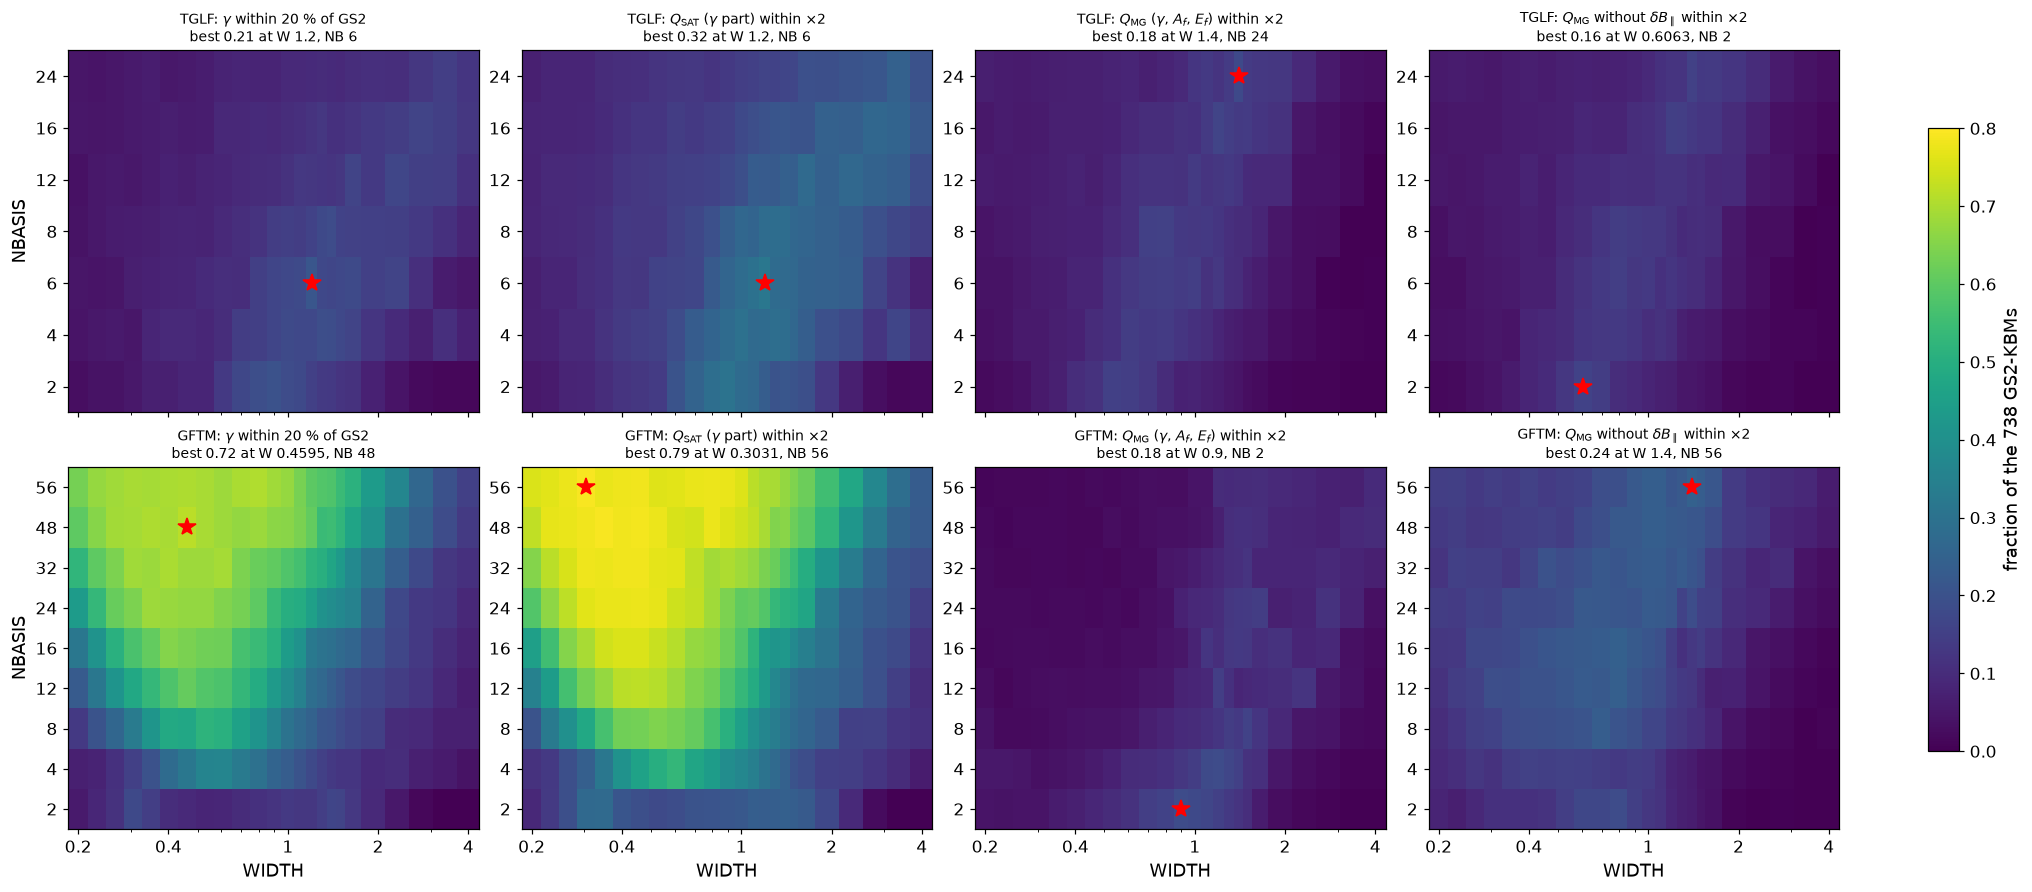

In [6]:
metrics = {"gamma_within_20%": r"$\gamma$ within 20 % of GS2",
           "q_sat_gamma_within_x2": r"$Q_{\rm SAT}$ ($\gamma$ part) within $\times2$",
           "q_mg_within_x2": r"$Q_{\rm MG}$ ($\gamma$, $A_f$, $E_f$) within $\times2$",
           "q_mg_no_bpar_within_x2": r"$Q_{\rm MG}$ without $\delta B_\parallel$ within $\times2$"}
fixed = ranked[ranked.family == "fixed"]
fig, axes = plt.subplots(2, len(metrics), figsize=(4.6 * len(metrics), 8), sharex=True)
for row, code in enumerate(cells):
    table = fixed[fixed.code == code]
    for col, (metric, label) in enumerate(metrics.items()):
        grid = table.pivot(index="nbasis", columns="width", values=metric)
        mesh = axes[row, col].pcolormesh(grid.columns, np.arange(len(grid.index)), grid.values, vmin=0, vmax=0.8,
                                         cmap="viridis", shading="nearest")
        axes[row, col].set_xscale("log")
        axes[row, col].set_xticks([0.2, 0.4, 1, 2, 4], ["0.2", "0.4", "1", "2", "4"])
        axes[row, col].xaxis.set_minor_formatter(plt.NullFormatter())
        axes[row, col].set_yticks(np.arange(len(grid.index)), grid.index)
        best = table.loc[table[metric].idxmax()]
        axes[row, col].plot(best.width, list(grid.index).index(best.nbasis), "r*", ms=12)
        axes[row, col].set_title(f"{code}: {label}\nbest {best[metric]:.2f} at W {best.width:g}, NB {best.nbasis:g}", fontsize=9)
        if col == 0:
            axes[row, col].set_ylabel("NBASIS")
        if row == 1:
            axes[row, col].set_xlabel("WIDTH")
fig.colorbar(mesh, ax=axes, label="fraction of the 738 GS2-KBMs", shrink=0.8)
fig.savefig(plot_dir / "plots" / "settings_metric_maps.png", dpi=150)

## Figure 2: TGLF GHAT (WIDTH 0.4, NBASIS 24), the three metrics and the median terms

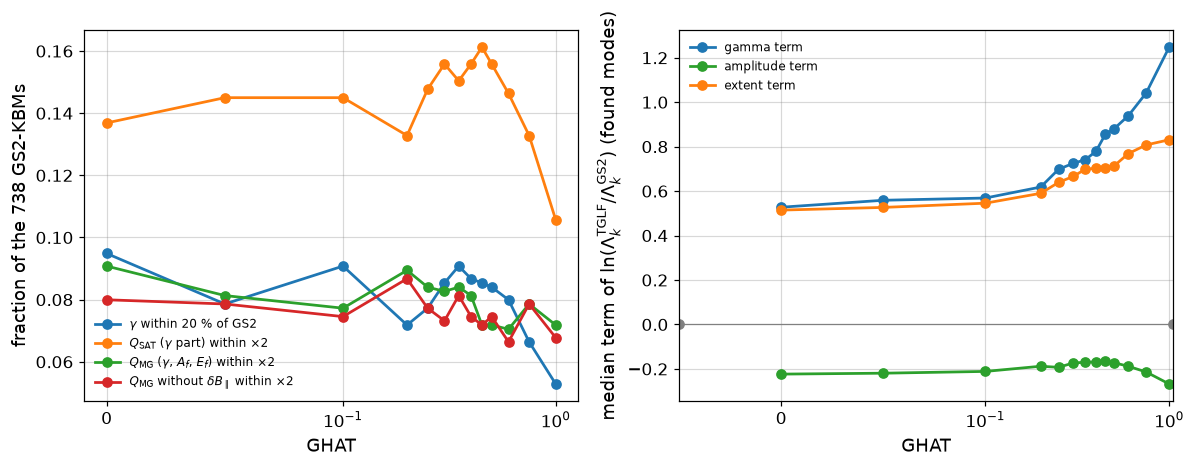

In [7]:
ghat_table = ranked[(ranked.code == "TGLF") & ((ranked.family == "ghat") | ((ranked.width == 0.4) & (ranked.nbasis == 24)))].sort_values("ghat")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for metric, label in metrics.items():
    axes[0].plot(ghat_table.ghat, ghat_table[metric], "o-", label=label)
axes[0].set_ylabel("fraction of the 738 GS2-KBMs")
for term, colour in zip(["gamma_term", "amplitude_term", "extent_term"], ["C0", "C2", "C1"]):
    axes[1].plot(ghat_table.ghat, ghat_table[f"median_{term}_found"], "o-", color=colour, label=term.replace("_", " "))
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_ylabel(r"median term of $\ln(\Lambda_k^{\rm TGLF}/\Lambda_k^{\rm GS2})$ (found modes)")
for ax in axes:
    ax.set_xscale("symlog", linthresh=0.1)
    ax.set_xlabel("GHAT")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(plot_dir / "plots" / "ghat_flux_metric.png", dpi=150)

## Figure 3: per mode, $\gamma$ error against eigenfunction ($S$) error, at the candidate settings
On the dashed line the $S$ error cancels the $\gamma$ error in $\Lambda_k$. Points above $y=0$: the eigenfunction raises
$\Lambda_k$.

gamma_term  amplitude_term  \
code family width  nbasis ghat                                              
GFTM fixed  0.3482 32     1.00 gamma_term            1.00            0.08   
                               amplitude_term        0.08            1.00   
                               extent_term           0.13            0.08   
            0.4000 12     1.00 gamma_term            1.00            0.04   
                               amplitude_term        0.04            1.00   
                               extent_term           0.17            0.07   
                   32     1.00 gamma_term            1.00            0.13   
                               amplitude_term        0.13            1.00   
                               extent_term           0.12            0.11   
            0.6063 32     1.00 gamma_term            1.00            0.19   
                               amplitude_term        0.19            1.00   
                               extent_term           0.14            0.15   
TGLF fixed  0.4000 24     1.00 gamma_term            1.00           -0.55   
                               amplitude_term       -0.55            1.00   
                               extent_term           0.18            0.03   
     ghat   0.4000 24     0.00 gamma_term            1.00           -0.40   
                               amplitude_term       -0.40            1.00   
                               extent_term           0.25            0.16   
                          0.25 gamma_term            1.00           -0.50   
                               amplitude_term       -0.50            1.00   
                               extent_term           0.20            0.07   

                                               extent_term  
code family width  nbasis ghat                              
GFTM fixed  0.3482 32     1.00 gamma_term             0.13  
                               amplitude_term         0.08  
                               extent_term            1.00  
            0.4000 12     1.00 gamma_term             0.17  
                               amplitude_term         0.07  
                               extent_term            1.00  
                   32     1.00 gamma_term             0.12  
                               amplitude_term         0.11  
                               extent_term            1.00  
            0.6063 32     1.00 gamma_term             0.14  
                               amplitude_term         0.15  
                               extent_term            1.00  
TGLF fixed  0.4000 24     1.00 gamma_term             0.18  
                               amplitude_term         0.03  
                               extent_term            1.00  
     ghat   0.4000 24     0.00 gamma_term             0.25  
                               amplitude_term         0.16  
                               extent_term            1.00  
                          0.25 gamma_term             0.20  
                               amplitude_term         0.07  
                               extent_term            1.00

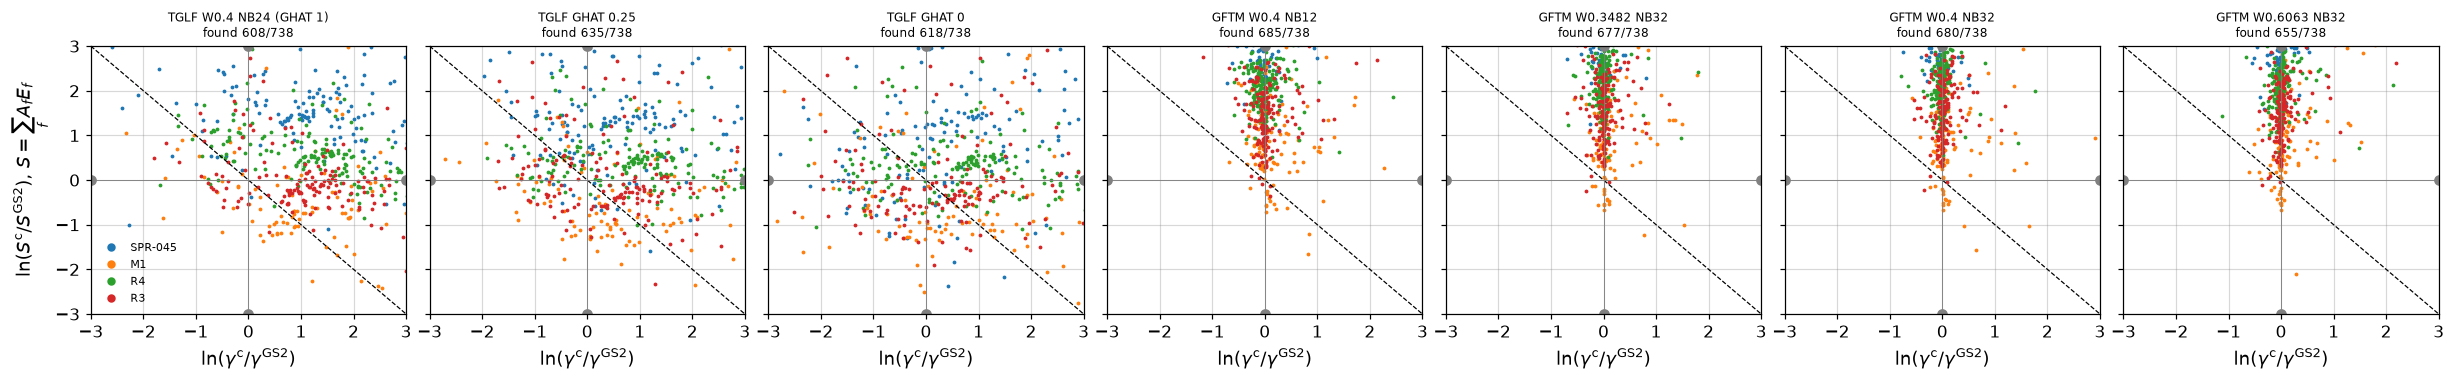

In [8]:
candidates = {"TGLF W0.4 NB24 (GHAT 1)": ("TGLF", "fixed", 0.4, 24, 1.0), "TGLF GHAT 0.25": ("TGLF", "ghat", 0.4, 24, 0.25),
              "TGLF GHAT 0": ("TGLF", "ghat", 0.4, 24, 0.0), "GFTM W0.4 NB12": ("GFTM", "fixed", 0.4, 12, 1.0),
              "GFTM W0.3482 NB32": ("GFTM", "fixed", 0.3482, 32, 1.0), "GFTM W0.4 NB32": ("GFTM", "fixed", 0.4, 32, 1.0),
              "GFTM W0.6063 NB32": ("GFTM", "fixed", 0.6063, 32, 1.0)}
indexed = runs.set_index(settings)
fig, axes = plt.subplots(1, len(candidates), figsize=(3.2 * len(candidates), 3.6), sharex=True, sharey=True)
for ax, (label, key) in zip(axes, candidates.items()):
    modes = indexed.loc[key]
    modes = modes[modes.found]
    for colour, case in zip(["C0", "C1", "C2", "C3"], cases):
        cell = modes[modes.case == case]
        ax.plot(cell.gamma_term, cell.amplitude_term + cell.extent_term, ".", ms=3, color=colour, label=case)
    ax.plot([-3, 3], [3, -3], "k--", lw=0.8)
    ax.axhline(0, color="grey", lw=0.6)
    ax.axvline(0, color="grey", lw=0.6)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(f"{label}\nfound {len(modes)}/738", fontsize=8)
    ax.set_xlabel(r"$\ln(\gamma^{\rm c}/\gamma^{\rm GS2})$")
axes[0].set_ylabel(r"$\ln(S^{\rm c}/S^{\rm GS2})$, $S=\sum_fA_fE_f$")
axes[0].legend(fontsize=7, markerscale=3)
fig.tight_layout()
fig.savefig(plot_dir / "plots" / "per_mode_gamma_vs_eigenfunction_error.png", dpi=150)
indexed.loc[list(candidates.values())].groupby(level=settings)[["gamma_term", "amplitude_term", "extent_term"]].apply(
    lambda frame: frame[np.isfinite(frame.gamma_term)].corr().round(2))

## Figure 4: which field's amplitude is wrong, against $k_y$
$\ln(A_f^{\rm code}/A_f^{\rm GS2})$ for $A_\parallel$ and $\delta B_\parallel$ per mode at the candidate settings. `gftm_bpar_ratio`
(`Fusion_PhD-38e9.26`) found GFTM's $\max|\delta B_\parallel|/\max|\phi|$ about $2/k_y$ times GS2's on other databases.

q_mg_within_x2  q_mg_no_bpar_within_x2  \
code family width  nbasis ghat                                           
TGLF fixed  0.4000 24     1.00           0.072                   0.068   
     ghat   0.4000 24     0.25           0.084                   0.077   
                          0.00           0.091                   0.080   
GFTM fixed  0.4000 12     1.00           0.026                   0.202   
            0.3482 32     1.00           0.016                   0.126   
            0.4000 32     1.00           0.015                   0.160   
            0.6063 32     1.00           0.024                   0.198   

                                median_log_amplitude_apar_found  \
code family width  nbasis ghat                                    
TGLF fixed  0.4000 24     1.00                           -0.547   
     ghat   0.4000 24     0.25                           -0.399   
                          0.00                           -0.487   
GFTM fixed  0.4000 12     1.00                            0.015   
            0.3482 32     1.00                            0.070   
            0.4000 32     1.00                            0.053   
            0.6063 32     1.00                            0.002   

                                median_log_amplitude_bpar_found  \
code family width  nbasis ghat                                    
TGLF fixed  0.4000 24     1.00                           -2.354   
     ghat   0.4000 24     0.25                           -1.693   
                          0.00                           -1.627   
GFTM fixed  0.4000 12     1.00                            3.495   
            0.3482 32     1.00                            3.602   
            0.4000 32     1.00                            3.615   
            0.6063 32     1.00                            3.571   

                                median_bpar_share_of_s_found  \
code family width  nbasis ghat                                 
TGLF fixed  0.4000 24     1.00                         0.009   
     ghat   0.4000 24     0.25                         0.013   
                          0.00                         0.015   
GFTM fixed  0.4000 12     1.00                         0.854   
            0.3482 32     1.00                         0.861   
            0.4000 32     1.00                         0.861   
            0.6063 32     1.00                         0.863   

                                median_bpar_share_of_s_gs2_found  
code family width  nbasis ghat                                    
TGLF fixed  0.4000 24     1.00                             0.092  
     ghat   0.4000 24     0.25                             0.089  
                          0.00                             0.087  
GFTM fixed  0.4000 12     1.00                             0.081  
            0.3482 32     1.00                             0.076  
            0.4000 32     1.00                             0.076  
            0.6063 32     1.00                             0.074

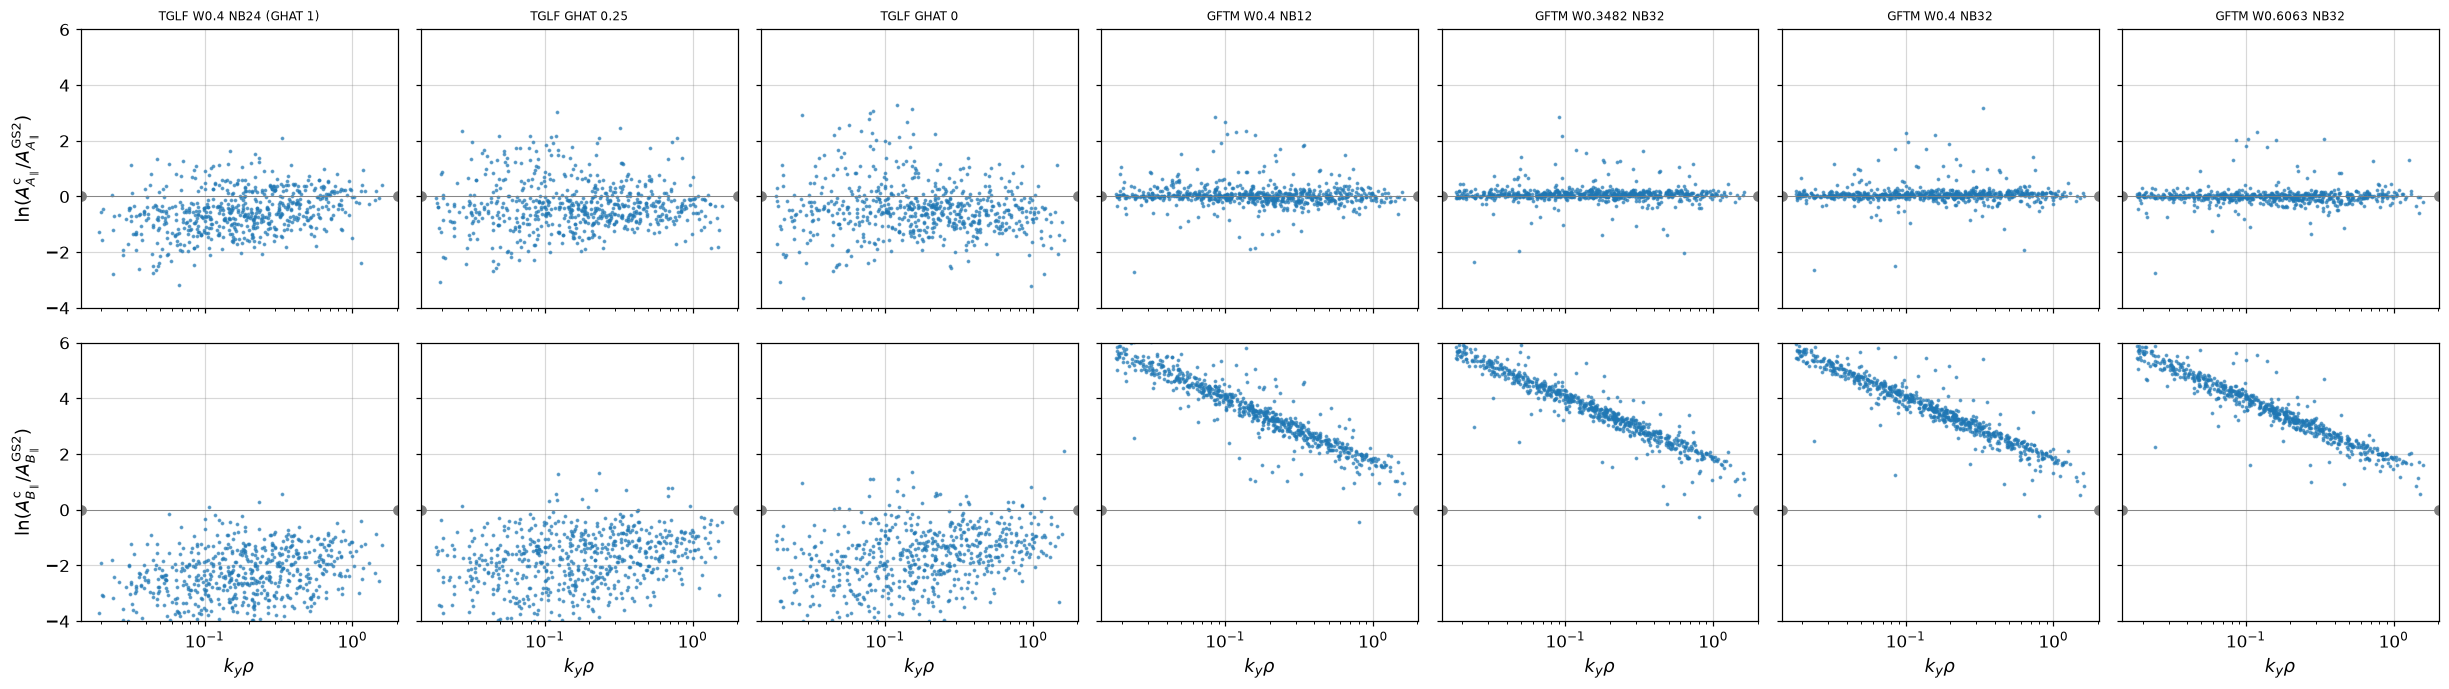

In [9]:
fig, axes = plt.subplots(2, len(candidates), figsize=(3.2 * len(candidates), 6.4), sharex=True, sharey=True)
for col, (label, key) in enumerate(candidates.items()):
    modes = indexed.loc[key]
    modes = modes[modes.found]
    for row, field in enumerate(["apar", "bpar"]):
        axes[row, col].semilogx(modes.ky, modes[f"log_amplitude_{field}"], ".", ms=3, alpha=0.6)
        axes[row, col].axhline(0, color="grey", lw=0.6)
        axes[row, col].set_ylim(-4, 6)
        if row == 0:
            axes[row, col].set_title(label, fontsize=8)
        if row == 1:
            axes[row, col].set_xlabel(r"$k_y\rho$")
    axes[0, 0].set_ylabel(r"$\ln(A_{A_\parallel}^{\rm c}/A_{A_\parallel}^{\rm GS2})$")
    axes[1, 0].set_ylabel(r"$\ln(A_{B_\parallel}^{\rm c}/A_{B_\parallel}^{\rm GS2})$")
fig.tight_layout()
fig.savefig(plot_dir / "plots" / "per_mode_field_amplitude_vs_ky.png", dpi=150)
ranked.set_index(settings).loc[list(candidates.values()), ["q_mg_within_x2", "q_mg_no_bpar_within_x2", "median_log_amplitude_apar_found",
                                                         "median_log_amplitude_bpar_found", "median_bpar_share_of_s_found",
                                                         "median_bpar_share_of_s_gs2_found"]].round(3)